In [1]:
##Imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
import itertools
from torch.nn import Parameter

import torch
import torch.fft as fft
import torchoptics
from torchoptics.profiles import gaussian, circle
from torchoptics.elements import PhaseModulator
from torchoptics import Field, System
from pyhank import HankelTransform

device = "cuda" if torch.cuda.is_available() else "cpu"

1st part: create a lens by reducing the problem to 1d thanks to the radial simmetry

In [2]:
# ==========================================
# PROGRAM 1: FUNCTIONS & INITIALIZATION
# ==========================================

def KtoR(k, waveLength, focalLength):
    return waveLength * focalLength * k / (2 * np.pi)


def RtoK(r, waveLength, focalLength):
    return 2 * np.pi * r / (waveLength * focalLength)


def MSE_w(goalProfile, iterProfile, weights):
    return np.sum(weights * (goalProfile - iterProfile) ** 2) / (np.sum(weights * goalProfile ** 2) + 1e-15)


def GerchbergSaxton(inputProfile, goalFunction, transformer, initial_doe, radius=100, maxiter=10000, errMin=1e-4,
                    initialSlope=8):
    N = len(goalFunction)
    r = transformer.r
    kr = transformer.kr

    P_in = 2 * np.pi * np.trapz(np.abs(inputProfile) ** 2 * r, r)
    P_goal = 2 * np.pi * np.trapz(np.abs(goalFunction) ** 2 * r, r)
    goalProfile = goalFunction * np.sqrt(P_in / P_goal)
    n = 2

    if len(initial_doe) == 0:
        testfit = np.array(
            [initialSlope * item * 1e2 * (item * 1e2) ** n / ((item * 1e2) ** n + 1) - 2.5 for item in r])
        U_DOE = np.exp(1j * testfit)
    else:
        U_DOE = initial_doe

    U_initial = transformer.qdht(inputProfile)
    weights = kr * np.gradient(kr)

    P_in = np.sum(weights * np.abs(U_initial) ** 2)
    P_goal = np.sum(weights * np.abs(goalFunction) ** 2)
    goalProfile = goalFunction * np.sqrt(P_in / P_goal)

    adaptive_goal = np.copy(goalProfile)

    for i in range(maxiter):
        U_tot = inputProfile * U_DOE
        U_image = transformer.qdht(U_tot)
        U_im_abs = np.abs(U_image)
        I_found = U_im_abs ** 2

        error = MSE_w(goalProfile, U_im_abs, weights)
        adaptive_goal = adaptive_goal + 0.5 * (goalProfile - U_im_abs)
        adaptive_goal[adaptive_goal < 0] = 0
        U_image = adaptive_goal * np.exp(1j * np.angle(U_image))

        if error < errMin:
            break

        U_DOE = transformer.iqdht(U_image)
        U_DOE = np.exp(1j * np.angle(U_DOE))

    return U_DOE


def wrap(angles):
    return (angles + np.pi) % (2 * np.pi) - np.pi


class GS_DOE:
    def __init__(self, params):
        self.setParams(params)

    def setParams(self, params):
        self.fl = params["fl"]
        self.wl = params["wl"]
        self.rmax = params["rmax"]
        self.N = params["N"]
        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def makeProfiles(self, p=3):
        self.transformer = HankelTransform(order=0, max_radius=self.rmax, n_points=self.N)
        self.r = self.transformer.r
        self.kr = self.transformer.kr
        self.inputAmp = np.exp(-(self.r / self.w0) ** 2)
        self.rho = self.wl * self.fl * self.transformer.kr / (2 * np.pi)
        self.goalProfile = np.exp(-(self.rho / self.wgoal) ** (2 * p))

    def makeDOE(self, initial_doe, initialSlope=8, maxiter=1000, errMin=1e-4):
        self.initialSlope = initialSlope
        self.DOE = GerchbergSaxton(self.inputAmp, self.goalProfile, self.transformer, initial_doe, radius=self.rmax,
                                   maxiter=maxiter,
                                   errMin=errMin, initialSlope=initialSlope)

    def getDOE(self):
        return self.DOE

From a radius, create the lenses by using different 'interpolation techniques'

In [3]:

def radial_to_2d(profile, radial_grid, N, rmax):

    shape = 2 * N - 1

    # Must match the spacing used by the PyTorch propagation
    dx = rmax / N

    coords = (
        np.arange(shape) - (shape - 1) / 2
    ) * dx

    X, Y = np.meshgrid(coords, coords, indexing='ij')

    R = np.sqrt(X**2 + Y**2)

    # Interpolate using the actual QDHT radial coordinates
    profile_2d = np.interp(
        R.ravel(),
        radial_grid,
        profile,
        left=profile[0],
        right=profile[-1]
    ).reshape(shape, shape)

    return profile_2d

def genLensPhase(N, wl, fl, dx):
    y, x = np.ogrid[-(N - 1):N, -(N - 1):N]
    r = np.sqrt(x ** 2 + y ** 2) * dx
    return -np.pi * r ** 2 / (wl * fl)


def create_interspersed_doe(DOEs: list, mirror: bool = False):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    g = 2 * radius_len
    merged_radius = np.zeros(radius_len)

    for r in range(radius_len):
        if mirror:
            cycle_len = 2 * n
            rem = r % cycle_len
            lens_idx = rem if rem < n else (cycle_len - 1 - rem)
        else:
            lens_idx = r % n
        profile = DOEs[lens_idx]
        merged_radius[r] = profile[r] if r < len(profile) else profile[-1]

    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]
    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.round(r_grid).astype(int)
    r_indices = np.clip(r_indices, 0, radius_len - 1)
    doe_grid = merged_radius[r_indices]
    return merged_radius, doe_grid


def create_permuted_sector_doe(DOEs: list, a: float):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    padded_DOEs = []
    for doe in DOEs:
        if len(doe) < radius_len:
            padded_DOEs.append(np.pad(doe, (0, radius_len - len(doe)), mode='edge'))
        else:
            padded_DOEs.append(doe[:radius_len])

    orig_stack = np.vstack(padded_DOEs)
    perms = list(itertools.permutations(range(n)))
    num_perms = len(perms)
    r_idx = np.arange(radius_len)
    base_lens_indices = r_idx % n

    aux_DOEs = []
    for p in perms:
        p_array = np.array(p)
        permuted_lens_indices = p_array[base_lens_indices]
        aux_radius = orig_stack[permuted_lens_indices, r_idx]
        aux_DOEs.append(aux_radius)

    num_sectors_exact = 360.0 / a
    num_sectors = int(np.round(num_sectors_exact))
    g = 2 * radius_len
    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]

    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.clip(np.round(r_grid).astype(int), 0, radius_len - 1)

    theta_grid = np.arctan2(y - center, x - center)
    theta_deg = np.degrees(theta_grid) % 360

    sector_idx = np.clip(np.floor(theta_deg / a).astype(int), 0, num_sectors - 1)
    aux_idx = sector_idx % num_perms
    aux_stack = np.vstack(aux_DOEs)
    doe_grid = aux_stack[aux_idx, r_indices]
    return doe_grid

Create and show the lenses

Generating baseline 1D GS DOEs...


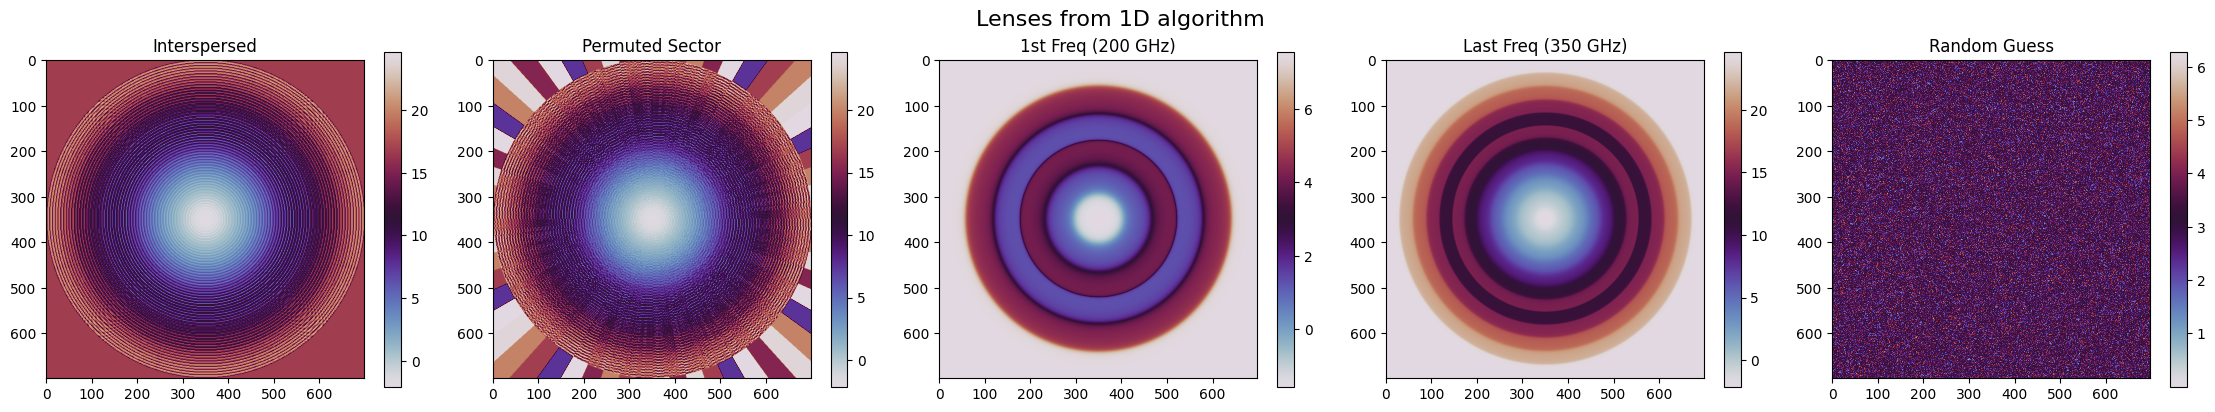

In [4]:

# ---------------------------------------------
# Generate Initial 1D Profiles 
# ---------------------------------------------
print("Generating baseline 1D GS DOEs...")
f0 = 200 * 1e9
does = []
radial_grid = None
for i in range(0, 6, 1):
    f = f0 + i * 30 * 1e9
    initial_doe = []
    params = {
        "fl": 15e-2,  # meters
        "wl": 3e8 / f,  # meters
        "rmax": 10e-2,  # meters
        "N": 350,
        "w0": 0.02,  # meters
        "wgoal": 0.008  # meters
    }
    DOE_maker = GS_DOE(params)
    DOE_maker.makeProfiles(p=4)
    DOE_maker.makeDOE(initial_doe, initialSlope=4, maxiter=250)
    does.append(np.unwrap(np.angle(DOE_maker.getDOE())))
    
    if radial_grid is None:
        radial_grid = DOE_maker.r.copy()
# Get specific 2D DOEs for PyTorch Initialization
_, prova1 = create_interspersed_doe(does)
prova1 = prova1[:-1, :-1]  # Crop to 699x699

prova3 = create_permuted_sector_doe(does, 360 / 1440)
prova3 = prova3[:-1, :-1]

does_0_2d = radial_to_2d(
    does[0],
    radial_grid,
    N=350,
    rmax=0.1
)
does_end_2d = radial_to_2d(
    does[-1],
    radial_grid,
    N=350,
    rmax=0.1
)

# --- NEW: Generate Random Phase Lens ---
shape_2d = 2 * params['N'] - 1
random_doe_2d = np.random.uniform(0, 2 * np.pi, size=(shape_2d, shape_2d))

# Lists to iterate for optimization (Added Random Lens)
initial_DOEs = [prova1, prova3, does_0_2d, does_end_2d, random_doe_2d]
titles = ["Interspersed", "Permuted Sector", "1st Freq (200 GHz)", "Last Freq (350 GHz)", "Random Guess"]

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, initial_DOEs, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Lenses from 1D algorithm", fontsize=16)
plt.tight_layout()
plt.show()


Codi a borrar. Té sentit que sa loss a nes principi per sa freq 200 és molt mes baix que la resta.

Using device: cpu

Optimizing: Single frequency 200 GHz
Iteration 50/500 | Mean Loss: 2.05432e-02 | Worst Loss: 3.66763e-02
Iteration 100/500 | Mean Loss: 2.06107e-02 | Worst Loss: 3.40409e-02
Iteration 150/500 | Mean Loss: 2.05443e-02 | Worst Loss: 3.40633e-02
Iteration 200/500 | Mean Loss: 2.05404e-02 | Worst Loss: 3.40426e-02
Iteration 250/500 | Mean Loss: 2.05409e-02 | Worst Loss: 3.40328e-02
Iteration 300/500 | Mean Loss: 2.05411e-02 | Worst Loss: 3.40302e-02
Iteration 350/500 | Mean Loss: 2.05412e-02 | Worst Loss: 3.40294e-02
Iteration 400/500 | Mean Loss: 2.05413e-02 | Worst Loss: 3.40291e-02
Iteration 450/500 | Mean Loss: 2.05413e-02 | Worst Loss: 3.40289e-02
Iteration 500/500 | Mean Loss: 2.05413e-02 | Worst Loss: 3.40288e-02

Broadband optimization complete.


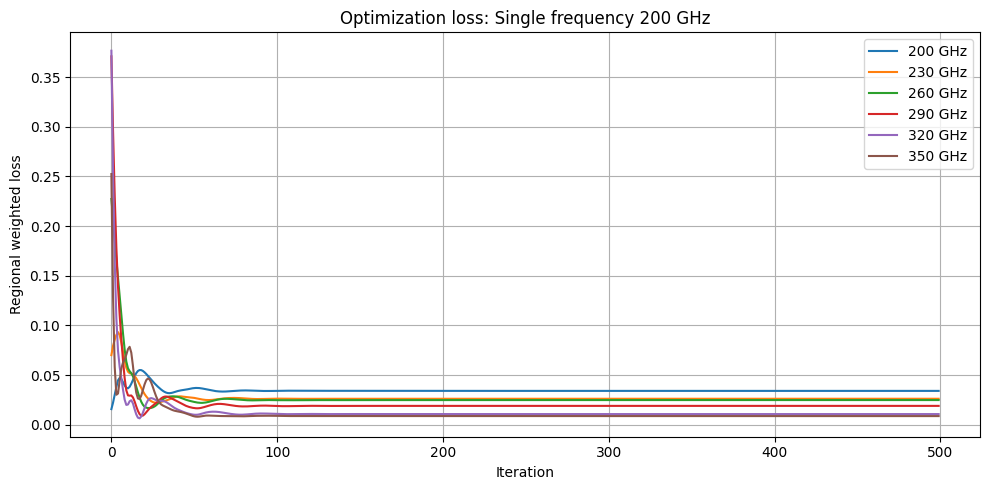

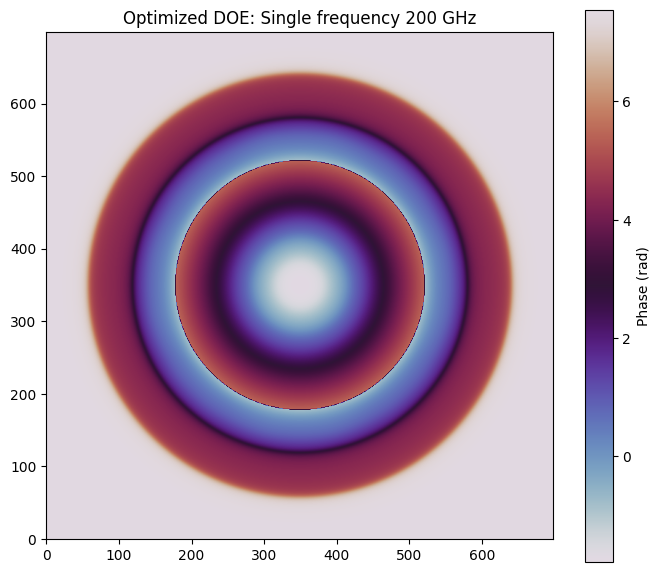

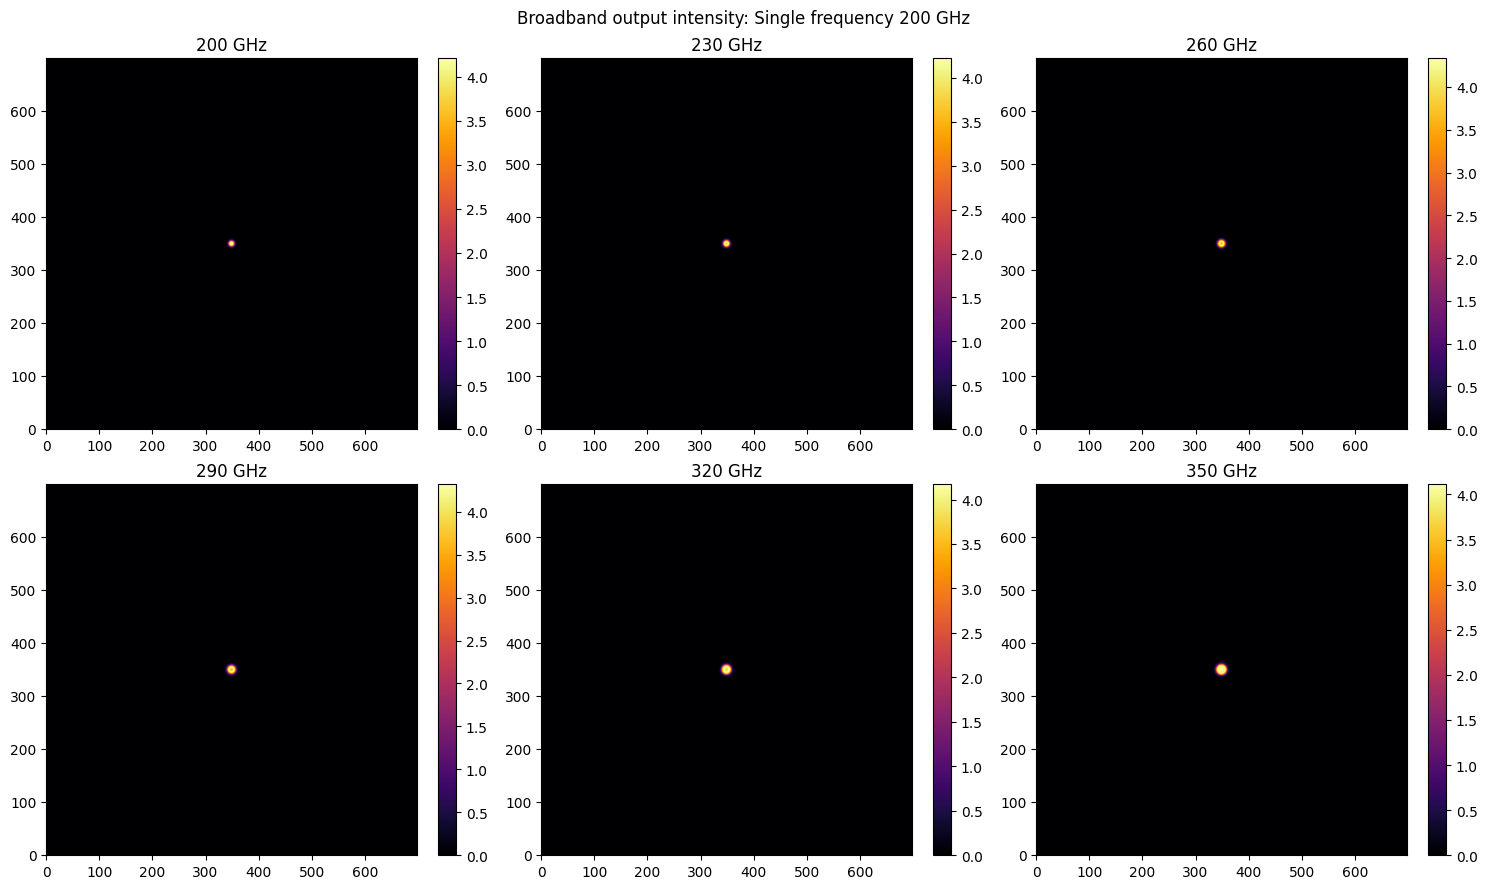

In [7]:

# ==========================================================
# PROGRAM 2: 2D BROADBAND DOE OPTIMIZATION
# FOURIER-TRANSFORM PROPAGATION
# ==========================================================

import numpy as np
import torch
import matplotlib.pyplot as plt

from torch import fft
from torch.nn import Parameter


# ==========================================================
# 1. PARAMETERS
# ==========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

N = params['N']
rmax = params['rmax']
w0 = params['w0']
wgoal = params['wgoal']
fl = params['fl']

shape = 2 * N - 1

dx = rmax / N

f0 = 200e9

frequencies = [
    f0 + i * 30e9 for i in range(6)
]

num_freq = len(frequencies)

# Super-Gaussian order
p = 4


# ==========================================================
# 2. LOSS PARAMETERS
# ==========================================================

w_center = 1.0
w_outer = 2.0
w_background = 1.0

# Importance of the worst-performing frequency
worst_weight = 0.5

# Adam parameters
learning_rate = 0.05
num_iterations = 500

# Physical DOE phase model:
# Continuous relief, nondispersive refractive index contrast
#
# phi(f) = phi(f0) * f/f0

def phase_frequency_scale(f):

    return f / f0


# ==========================================================
# 3. INPUT FIELD
# ==========================================================

coords = (
    torch.arange(shape, device=device) -
    (shape - 1) / 2
) * dx

X, Y = torch.meshgrid(
    coords,
    coords,
    indexing='ij'
)

R = torch.sqrt(X**2 + Y**2)

# Circular aperture matching the 1D radial domain
aperture = (R <= rmax).float()

# Gaussian input amplitude
source_profile = (
    torch.exp(-(R / w0)**2) * aperture
).to(torch.float32)

# Incident optical power (discrete approximation)
P_in = torch.sum(
    source_profile**2
) * dx**2


# ==========================================================
# 4. FOURIER FREQUENCY GRID
# ==========================================================

fx = fft.fftshift(
    fft.fftfreq(
        shape,
        d=dx,
        device=device
    )
)

fy = fft.fftshift(
    fft.fftfreq(
        shape,
        d=dx,
        device=device
    )
)

FX, FY = torch.meshgrid(
    fx,
    fy,
    indexing='ij'
)


# ==========================================================
# 5. FREQUENCY-DEPENDENT TARGETS
# ==========================================================

target_intensities = []
target_amplitudes = []

center_masks = []
outer_masks = []
background_masks = []

output_pixel_areas = []

center_radius = 0.5 * wgoal
outer_radius = 1.25 * wgoal

for f in frequencies:

    wavelength = 3e8 / f

    # --------------------------------------
    # Physical focal-plane coordinates
    # --------------------------------------

    XF = wavelength * fl * FX
    YF = wavelength * fl * FY

    RF = torch.sqrt(XF**2 + YF**2)

    # Focal-plane pixel spacing
    dxf = wavelength * fl / (shape * dx)

    pixel_area = dxf**2

    output_pixel_areas.append(pixel_area)

    # --------------------------------------
    # Super-Gaussian target amplitude
    # --------------------------------------

    A_target = torch.exp(
        -(RF / wgoal)**(2 * p)
    )

    I_target = A_target**2

    # --------------------------------------
    # Normalize target power
    # --------------------------------------

    P_target = torch.sum(
        I_target
    ) * pixel_area

    I_target = I_target * (P_in / P_target)

    A_target = torch.sqrt(I_target)

    target_amplitudes.append(A_target)
    target_intensities.append(I_target)

    # --------------------------------------
    # Regional masks
    # --------------------------------------

    center_masks.append(
        (RF <= center_radius).float()
    )

    outer_masks.append(
        (
            (RF > center_radius) &
            (RF <= outer_radius)
        ).float()
    )

    background_masks.append(
        (RF > outer_radius).float()
    )


# ==========================================================
# 6. 2D FOURIER PROPAGATION
# ==========================================================

def fourier_propagation(E1, wavelength):

    # Centered 2D Fourier transform
    E_fft = fft.fftshift(
        fft.fft2(
            fft.ifftshift(E1)
        )
    )

    # Physical Fraunhofer focal-plane amplitude
    E2 = (
        dx**2 / (wavelength * fl)
    ) * E_fft

    return E2


# ==========================================================
# 7. REGIONAL LOSS
# ==========================================================

def calculate_regional_loss(
    I_out,
    I_target,
    center_mask,
    outer_mask,
    background_mask
):

    # Normalize all errors by target peak intensity
    intensity_scale = torch.max(I_target)

    normalized_error = (
        (I_out - I_target) / intensity_scale
    )**2

    eps = 1e-12

    def region_loss(error, mask):

        return (
            torch.sum(error * mask) /
            (torch.sum(mask) + eps)
        )

    L_center = region_loss(
        normalized_error,
        center_mask
    )

    L_outer = region_loss(
        normalized_error,
        outer_mask
    )

    L_background = region_loss(
        normalized_error,
        background_mask
    )

    total = (
        w_center * L_center
        + w_outer * L_outer
        + w_background * L_background
    )

    return total


# ==========================================================
# 8. INITIAL DOE CONFIGURATIONS
# ==========================================================

# Ensure that these arrays were generated in Program 1.
#
# For the first experiment, use the 200 GHz DOE.

initial_DOEs = [
    does_0_2d
]

titles = [
    "Single frequency 200 GHz"
]

# You can later add:
#
# initial_DOEs = [
#     prova1,
#     prova3,
#     does_0_2d,
#     does_end_2d,
#     random_doe_2d
# ]
#
# Make sure all phase arrays have shape (699, 699).


# ==========================================================
# 9. BROADBAND OPTIMIZATION
# ==========================================================

optimized_phases = []
optimized_outputs = []
optimized_freq_outputs = []

all_loss_histories = []

for init_doe, title in zip(initial_DOEs, titles):

    print("\n========================================")
    print("Optimizing:", title)
    print("========================================")

    # --------------------------------------
    # Initialize continuous DOE phase
    # --------------------------------------

    initial_phase = torch.as_tensor(
        np.asarray(init_doe),
        device=device,
        dtype=torch.float32
    )

    if initial_phase.shape != (shape, shape):
        raise ValueError(
            f"Incorrect DOE shape: {initial_phase.shape}. "
            f"Expected {(shape, shape)}"
        )

    phi = Parameter(
        initial_phase.clone()
    )

    optimizer = torch.optim.Adam(
        [phi],
        lr=learning_rate
    )

    loss_history = []
    freq_loss_history = []

    # --------------------------------------
    # Adam iterations
    # --------------------------------------

    for it in range(num_iterations):

        optimizer.zero_grad()

        frequency_losses = []

        # ----------------------------------
        # Propagation at all frequencies
        # ----------------------------------

        for f_idx, f in enumerate(frequencies):

            wavelength = 3e8 / f

            # Physical phase delay of the DOE
            phi_f = (
                phi * phase_frequency_scale(f)
            )

            # Field immediately after DOE
            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            )

            # 2D Fourier propagation
            E2 = fourier_propagation(
                E1,
                wavelength
            )

            # Output intensity
            I_out = torch.abs(E2)**2

            # Frequency-dependent target
            I_target = target_intensities[f_idx]

            # Regional masks
            mc = center_masks[f_idx]
            mo = outer_masks[f_idx]
            mb = background_masks[f_idx]

            # Regional loss
            loss_f = calculate_regional_loss(
                I_out,
                I_target,
                mc,
                mo,
                mb
            )

            frequency_losses.append(loss_f)

        # ----------------------------------
        # Average + worst-frequency loss
        # ----------------------------------

        frequency_losses = torch.stack(
            frequency_losses
        )

        mean_loss = torch.mean(
            frequency_losses
        )

        worst_loss = torch.max(
            frequency_losses
        )

        total_loss = (
            mean_loss +
            worst_weight * worst_loss
        )

        # ----------------------------------
        # Backpropagation and Adam
        # ----------------------------------

        total_loss.backward()

        optimizer.step()

        # Store losses
        loss_history.append(
            mean_loss.item()
        )

        freq_loss_history.append(
            frequency_losses.detach().cpu().numpy()
        )

        if (it + 1) % 50 == 0:

            print(
                f"Iteration {it+1}/{num_iterations} | "
                f"Mean Loss: {mean_loss.item():.5e} | "
                f"Worst Loss: {worst_loss.item():.5e}"
            )

    # ======================================================
    # 10. SAVE OPTIMIZED DOE
    # ======================================================

    phi_final = phi.detach()

    optimized_phases.append(
        phi_final.cpu().numpy()
    )

    all_loss_histories.append(
        np.array(freq_loss_history)
    )

    # ======================================================
    # 11. FINAL PROPAGATION AT ALL FREQUENCIES
    # ======================================================

    freq_Is = []

    avg_I = torch.zeros(
        (shape, shape),
        device=device,
        dtype=torch.float32
    )

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies):

            wavelength = 3e8 / f

            phi_f = (
                phi_final * phase_frequency_scale(f)
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            )

            E2 = fourier_propagation(
                E1,
                wavelength
            )

            I_f = torch.abs(E2)**2

            freq_Is.append(
                I_f.cpu().numpy()
            )

            avg_I += I_f

    avg_I /= num_freq

    optimized_outputs.append(
        avg_I.cpu().numpy()
    )

    optimized_freq_outputs.append(
        freq_Is
    )

print("\nBroadband optimization complete.")


# ==========================================================
# 12. PLOT OPTIMIZATION LOSSES
# ==========================================================

for lens_idx, title in enumerate(titles):

    losses = all_loss_histories[lens_idx]

    plt.figure(figsize=(10, 5))

    for f_idx, f in enumerate(frequencies):

        plt.plot(
            losses[:, f_idx],
            label=f'{f/1e9:.0f} GHz'
        )

    plt.xlabel("Iteration")
    plt.ylabel("Regional weighted loss")
    plt.title(f"Optimization loss: {title}")

    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()


# ==========================================================
# 13. PLOT FINAL DOE PHASE
# ==========================================================

for lens_idx, title in enumerate(titles):

    plt.figure(figsize=(7, 6))

    plt.imshow(
        optimized_phases[lens_idx],
        cmap='twilight',
        origin='lower'
    )

    plt.colorbar(label='Phase (rad)')
    plt.title(f"Optimized DOE: {title}")
    plt.tight_layout()
    plt.show()


# ==========================================================
# 14. PLOT FINAL OUTPUT INTENSITIES
# ==========================================================

for lens_idx, title in enumerate(titles):

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9)
    )

    for f_idx, f in enumerate(frequencies):

        ax = axes.flat[f_idx]

        im = ax.imshow(
            optimized_freq_outputs[lens_idx][f_idx],
            cmap='inferno',
            origin='lower'
        )

        ax.set_title(
            f'{f/1e9:.0f} GHz'
        )

        fig.colorbar(
            im,
            ax=ax,
            fraction=0.046
        )

    fig.suptitle(
        f"Broadband output intensity: {title}"
    )

    plt.tight_layout()
    plt.show()


2nd part: 2d algorithm to optimize without symetry

Plot the results

Option 2: a more complex Loss function that takes into account the different regions of the plane, so can give more weight to the central region, but also assigns different weights to the average over frequencies and to the worse frequency.


Starting multi-frequency PyTorch Optimization...

Optimizing: Interspersed
Iteration 100/100 | Mean Loss: 3.44165e-02 | Worst Loss: 4.26598e-02


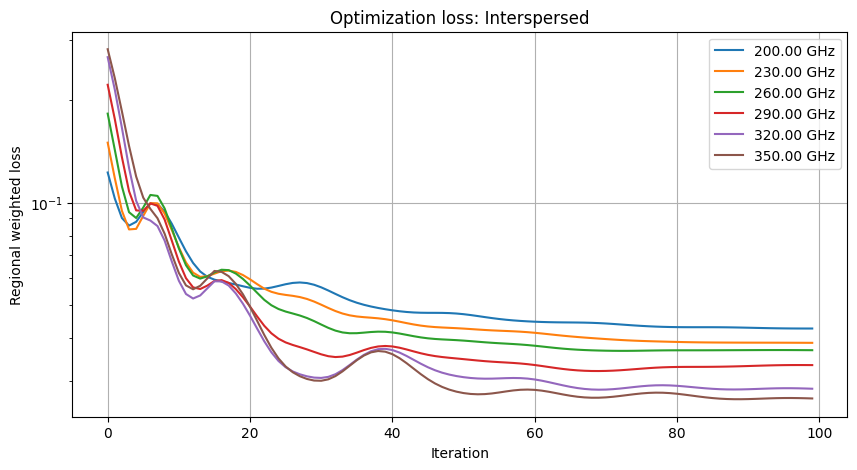


Optimizing: Permuted Sector
Iteration 100/100 | Mean Loss: 3.43766e-02 | Worst Loss: 4.23634e-02


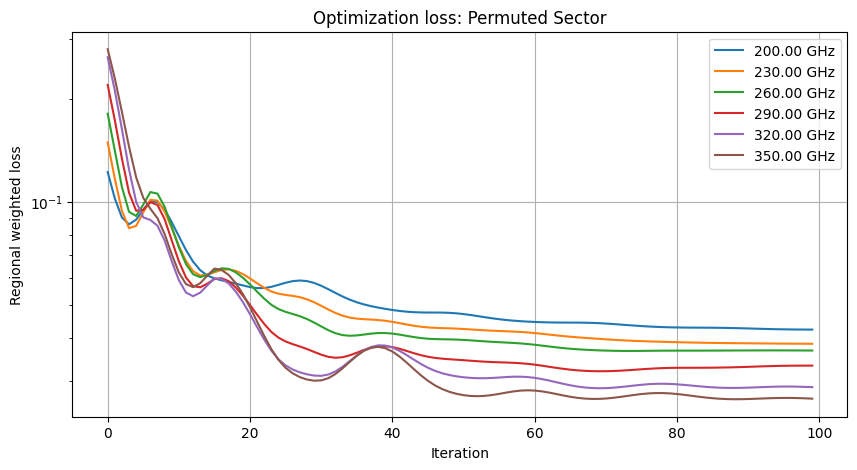


Optimizing: 1st Freq (200 GHz)
Iteration 100/100 | Mean Loss: 3.28173e-02 | Worst Loss: 4.14632e-02


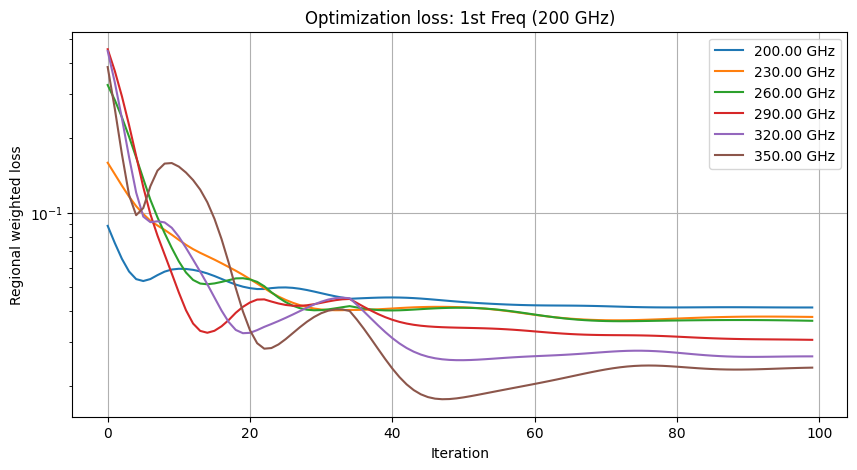


Optimizing: Last Freq (350 GHz)
Iteration 100/100 | Mean Loss: 4.15812e-02 | Worst Loss: 4.98135e-02


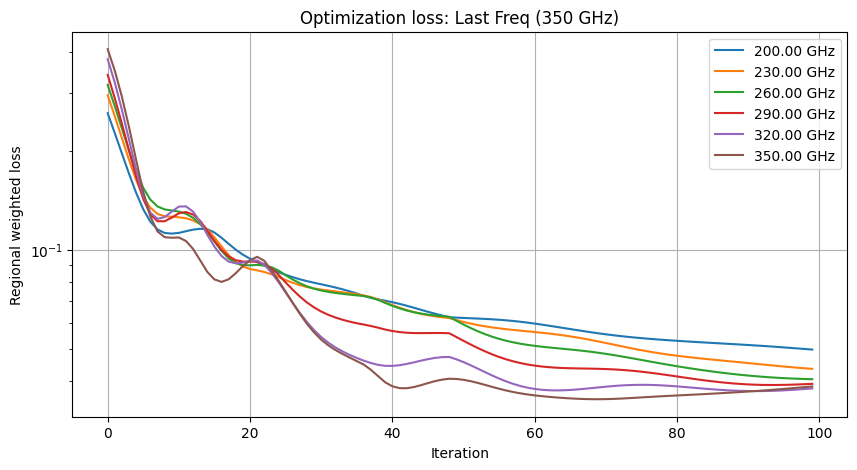


Optimizing: Random Guess
Iteration 100/100 | Mean Loss: 2.05564e-01 | Worst Loss: 2.58134e-01


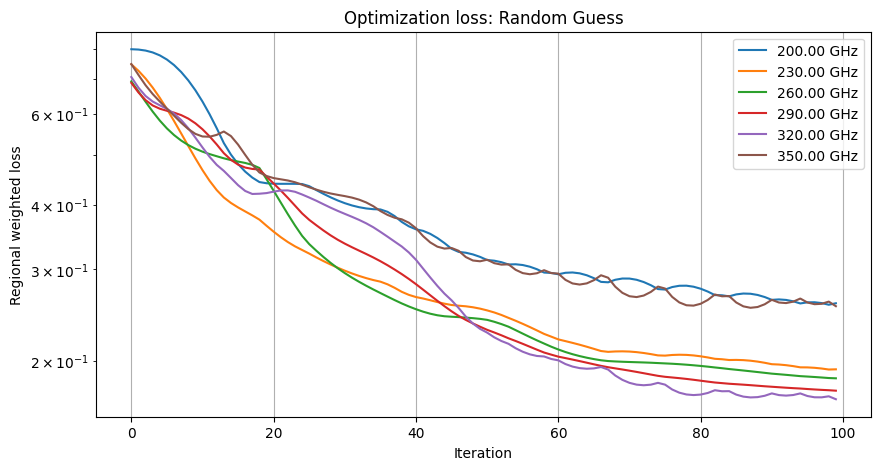


Optimization Complete.


In [19]:


# ==========================================
# PROGRAM 2: PYTORCH MULTI-FREQUENCY OPTIMIZATION
# FRAUNHOFER PROPAGATION THROUGH A FOCUSING LENS
# WITH REGIONAL WEIGHTED LOSS
# ==========================================

print("\nStarting multi-frequency PyTorch Optimization...")

dx = params['rmax'] / params['N']
shape = 2 * params['N'] - 1

torchoptics.set_default_spacing(dx)

fl = params['fl']
wgoal = params['wgoal']

# Reference frequency
frequencies = [f0 + i * 30 * 1e9 for i in range(6)]

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]


# ==========================================
# 1. SOURCE PROFILE
# ==========================================

source_profile = gaussian(
    shape,
    waist_radius=params['w0']
).to(device, dtype=torch.float32)

# Incident power (physical discrete approximation)
P_in = torch.sum(
    torch.abs(source_profile)**2
) * dx**2


# ==========================================
# 2. SPATIAL COORDINATES AT DOE PLANE
# ==========================================

coords = (
    torch.arange(shape, device=device, dtype=torch.float32)
    - (shape - 1) / 2
) * dx

X, Y = torch.meshgrid(
    coords,
    coords,
    indexing='ij'
)

R = torch.sqrt(X**2 + Y**2)


# ==========================================
# 3. DOE PHASE FREQUENCY DEPENDENCE
# ==========================================

# Assumption:
# The DOE is a continuous physical relief with
# approximately frequency-independent refractive
# index contrast.
#
# Therefore, phase delay is proportional to frequency.

def phase_frequency_scale(f):

    return f / f0


# If you instead want an ideal frequency-independent
# phase mask, replace the previous function with:
#
# def phase_frequency_scale(f):
#     return 1.0


# ==========================================
# 4. FRAUNHOFER PROPAGATION
# ==========================================

def fraunhofer_propagation(E1, f):

    wavelength = 3e8 / f

    # Centered 2D Fourier transform
    E_fft = fft.fftshift(
        fft.fft2(
            fft.ifftshift(E1)
        )
    )

    # Physical Fraunhofer focal-plane field
    E2 = (
        dx**2 / (1j * wavelength * fl)
    ) * E_fft

    return E2


# ==========================================
# 5. FREQUENCY-DEPENDENT TARGETS AND MASKS
# ==========================================

# Store target intensity distributions and regional masks
target_intensities = []
center_masks = []
outer_masks = []
background_masks = []

focal_plane_coordinates = []
focal_plane_spacings = []

# Regional radii
center_radius = 0.5 * wgoal
outer_radius = wgoal

for f in frequencies:

    wavelength = 3e8 / f

    # --------------------------------------
    # Focal-plane spatial frequency grid
    # --------------------------------------

    fx = fft.fftshift(
        fft.fftfreq(
            shape,
            d=dx,
            device=device
        )
    )

    fy = fft.fftshift(
        fft.fftfreq(
            shape,
            d=dx,
            device=device
        )
    )

    FX, FY = torch.meshgrid(
        fx, fy,
        indexing='ij'
    )

    # --------------------------------------
    # Physical focal-plane coordinates
    # --------------------------------------

    XF = wavelength * fl * FX
    YF = wavelength * fl * FY

    RF = torch.sqrt(XF**2 + YF**2)

    # Focal-plane pixel spacing
    dxf = wavelength * fl / (shape * dx)

    focal_plane_coordinates.append((XF, YF))
    focal_plane_spacings.append(dxf)

    # --------------------------------------
    # Circular target
    # --------------------------------------

    target_mask_f = (
        RF <= wgoal
    ).to(torch.float32)

    # Normalize target power to incident power
    P_tgt = (
        torch.sum(target_mask_f) * dxf**2
    )

    I_tgt_f = (
        target_mask_f * (P_in / P_tgt)
    ).to(torch.float32)

    target_intensities.append(I_tgt_f)

    # --------------------------------------
    # Regional masks
    # --------------------------------------

    center_masks.append(
        (RF <= center_radius).to(torch.float32)
    )

    outer_masks.append(
        (
            (RF > center_radius) &
            (RF <= outer_radius)
        ).to(torch.float32)
    )

    background_masks.append(
        (RF > outer_radius).to(torch.float32)
    )


# Keep the original single-frequency variable names
# for compatibility with the previous implementation.

target_profile = target_intensities[0]
target_mask = (target_profile > 0).to(torch.float32)
I_tgt = target_profile

center_mask = center_masks[0]
outer_mask = outer_masks[0]
background_mask = background_masks[0]


# ==========================================
# 6. REGIONAL LOSS FUNCTION
# ==========================================

w_center = 0.4
w_outer = 0.4
w_background = 0.2


def regional_loss(
    I_out,
    I_target,
    center_mask_f,
    outer_mask_f,
    background_mask_f
):

    # Normalize the error to avoid excessively
    # large loss values due to physical intensity units.

    intensity_scale = torch.max(I_target)

    normalized_error = (
        (I_out - I_target) / (intensity_scale + 1e-12)
    )**2

    eps = 1e-12

    # Center region
    loss_center = torch.sum(
        center_mask_f * normalized_error
    ) / (torch.sum(center_mask_f) + eps)

    # Outer region
    loss_outer = torch.sum(
        outer_mask_f * normalized_error
    ) / (torch.sum(outer_mask_f) + eps)

    # Background
    loss_background = torch.sum(
        background_mask_f * normalized_error
    ) / (torch.sum(background_mask_f) + eps)

    # Weighted loss
    loss = (
        w_center * loss_center
        + w_outer * loss_outer
        + w_background * loss_background
    )

    return loss


# ==========================================
# 7. OPTIMIZATION PARAMETERS
# ==========================================

optimized_phases = []
optimized_outputs = []
optimized_outputs_2 = []

optimized_freq_outputs = []
optimized_freq_2_outputs = []

# Worst-frequency importance
rho = 0.5

num_iterations = 100

learning_rate = 0.05


# ==========================================
# 8. MULTI-FREQUENCY DOE OPTIMIZATION
# ==========================================

for init_doe, title in zip(initial_DOEs, titles):

    print(f"\nOptimizing: {title}")

    # --------------------------------------
    # Initialize DOE phase
    # --------------------------------------

    initial_phase = torch.tensor(
        init_doe,
        device=device,
        dtype=torch.float32
    )

    phi = torch.nn.Parameter(
        initial_phase.clone()
    )

    # Adam optimizer
    optimizer = torch.optim.Adam(
        [phi],
        lr=learning_rate
    )

    # Store loss evolution
    loss_history = []

    # ======================================
    # ADAM ITERATIONS
    # ======================================

    for it in range(num_iterations):

        optimizer.zero_grad()

        losses = []

        # ----------------------------------
        # Propagation at all frequencies
        # ----------------------------------

        for f_idx, f in enumerate(frequencies):

            wavelength = 3e8 / f

            # Frequency-dependent physical DOE phase
            phi_f = phi * phase_frequency_scale(f)

            # Field immediately after DOE
            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            # Fraunhofer propagation
            E2 = fraunhofer_propagation(
                E1, f
            )

            # Output intensity
            I_out = torch.abs(E2)**2

            # Frequency-dependent target
            I_target = target_intensities[f_idx]

            # Regional weighted loss
            loss_f = regional_loss(
                I_out,
                I_target,
                center_masks[f_idx],
                outer_masks[f_idx],
                background_masks[f_idx]
            )

            losses.append(loss_f)

        # ----------------------------------
        # Multi-frequency objective
        # ----------------------------------

        losses = torch.stack(losses)

        mean_loss = torch.mean(losses)

        worst_loss = torch.max(losses)

        loss = (
            (1 - rho) * mean_loss
            + rho * worst_loss
        )

        # ----------------------------------
        # Backpropagation and Adam
        # ----------------------------------

        loss.backward()

        optimizer.step()

        loss_history.append(
            losses.detach().cpu().numpy()
        )

        # ----------------------------------
        # Progress information
        # ----------------------------------

        if (it + 1) % 100 == 0:

            print(
                f"Iteration {it + 1}/{num_iterations} | "
                f"Mean Loss: {mean_loss.item():.5e} | "
                f"Worst Loss: {worst_loss.item():.5e}"
            )


    # ======================================
    # 9. STORE OPTIMIZED DOE
    # ======================================

    optimized_phases.append(
        phi.detach().cpu().numpy()
    )


    # ======================================
    # 10. FINAL OUTPUT: FIRST FREQUENCY SET
    # ======================================

    avg_I = torch.zeros(
        (shape, shape),
        device=device,
        dtype=torch.float32
    )

    freq_Is = []

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies):

            phi_f = phi * phase_frequency_scale(f)

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            E2 = fraunhofer_propagation(
                E1, f
            )

            I_f = torch.abs(E2)**2

            freq_Is.append(
                I_f.cpu().numpy()
            )

            avg_I += I_f

    avg_I /= len(frequencies)

    optimized_outputs.append(
        avg_I.cpu().numpy()
    )

    optimized_freq_outputs.append(freq_Is)


    # ======================================
    # 11. FINAL OUTPUT: SECOND FREQUENCY SET
    # ======================================

    avg_I_2 = torch.zeros(
        (shape, shape),
        device=device,
        dtype=torch.float32
    )

    freq_2_Is = []

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies_2):

            phi_f = phi * phase_frequency_scale(f)

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            E2 = fraunhofer_propagation(
                E1, f
            )

            I_f = torch.abs(E2)**2

            freq_2_Is.append(
                I_f.cpu().numpy()
            )

            avg_I_2 += I_f

    avg_I_2 /= len(frequencies_2)

    optimized_outputs_2.append(
        avg_I_2.cpu().numpy()
    )

    optimized_freq_2_outputs.append(freq_2_Is)


    # ======================================
    # 12. PLOT LOSS EVOLUTION
    # ======================================

    loss_history = np.array(loss_history)

    plt.figure(figsize=(10, 5))

    for i, f in enumerate(frequencies):

        plt.semilogy(
            loss_history[:, i],
            label=f'{f/1e9:.2f} GHz'
        )

    plt.xlabel('Iteration')
    plt.ylabel('Regional weighted loss')
    plt.title(f'Optimization loss: {title}')

    plt.legend()
    plt.grid()
    plt.show()


print("\nOptimization Complete.")


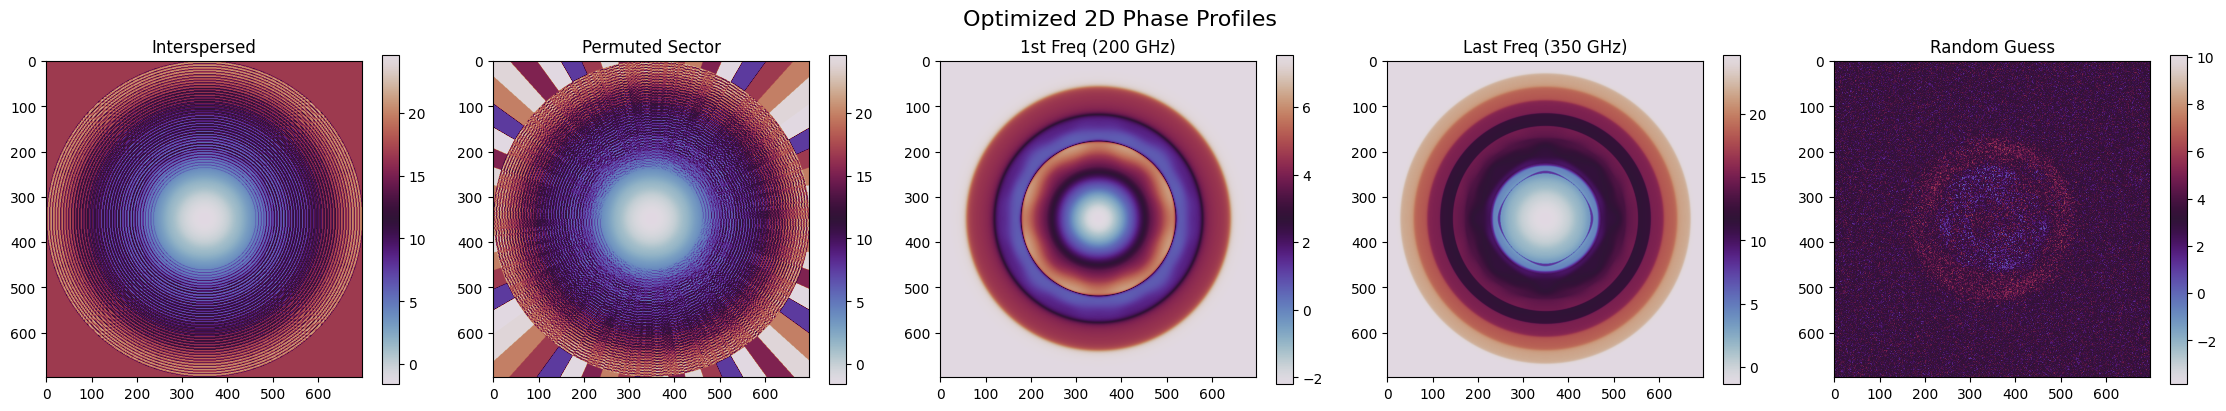

In [20]:
# ==========================================
# PLOTTING RESULTS
# ==========================================

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, optimized_phases, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Optimized 2D Phase Profiles", fontsize=16)
plt.tight_layout()
plt.show()

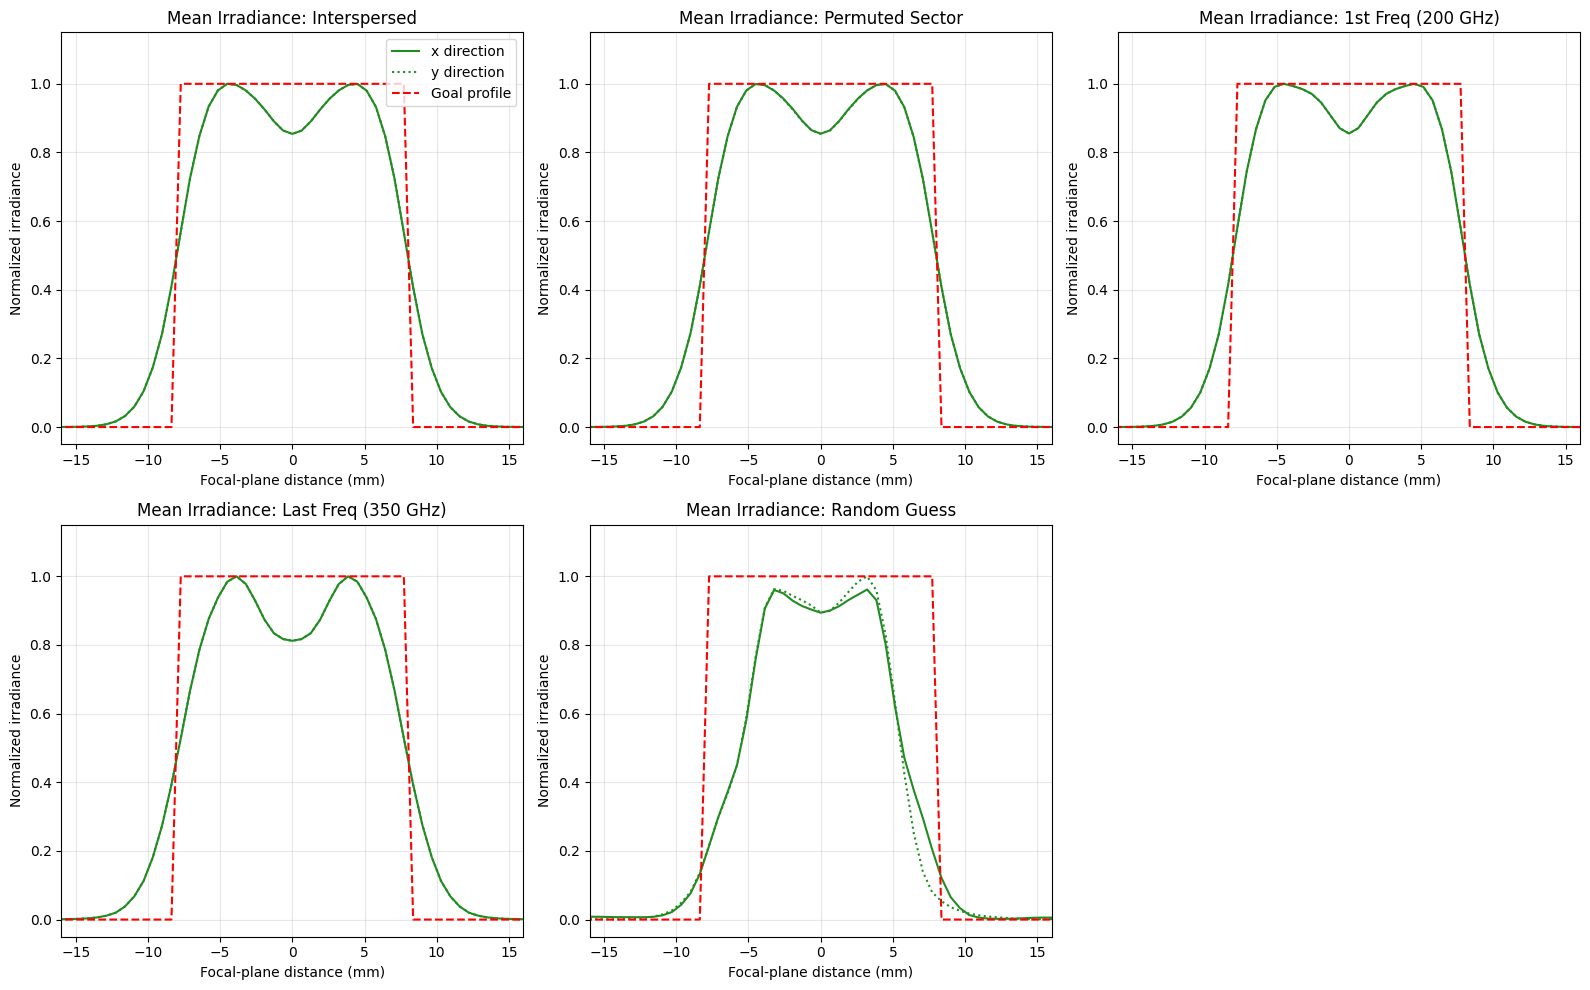

In [21]:

from scipy.ndimage import map_coordinates

# ==========================================
# CROSS-SECTION IRRADIANCE: PHYSICAL COORDINATES
# ==========================================

fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
axes2 = axes2.flatten()

num_lenses = len(optimized_freq_outputs)

center_idx = params['N'] - 1

wgoal_mm = params['wgoal'] * 1000

# ------------------------------------------
# 1. Calculate focal-plane sampling
# ------------------------------------------

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return wavelength * params['fl'] / (
        shape * dx
    )


# Use the finest sampling among the frequencies
# as the common physical grid.

dxf_values = [
    focal_plane_spacing(f)
    for f in frequencies
]

dxf_common = min(dxf_values)

# Common physical coordinates, centered at zero
x_common = (
    np.arange(shape) - center_idx
) * dxf_common

distance_mm = x_common * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(distance_mm) <= wgoal_mm
).astype(float)


# ==========================================
# 2. RESAMPLE AND AVERAGE ALL FREQUENCIES
# ==========================================

averaged_physical_outputs = []

for lens_idx, title in enumerate(titles):

    freq_Is = optimized_freq_outputs[lens_idx]

    resampled_Is = []

    # Common coordinate grid in physical meters
    X_common, Y_common = np.meshgrid(
        x_common,
        x_common,
        indexing='xy'
    )

    # --------------------------------------
    # Interpolate each frequency
    # --------------------------------------

    for f_idx, f in enumerate(frequencies):

        I_f = freq_Is[f_idx]

        dxf = focal_plane_spacing(f)

        # Convert common physical coordinates
        # into pixel indices of the original image.

        ix = center_idx + X_common / dxf
        iy = center_idx + Y_common / dxf

        # Bilinear interpolation
        I_resampled = map_coordinates(
            I_f,
            [iy, ix],
            order=1,
            mode='constant',
            cval=0.0
        )

        resampled_Is.append(I_resampled)

    # --------------------------------------
    # Average on the common physical grid
    # --------------------------------------

    avg_I_common = np.mean(
        resampled_Is,
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_common
    )

    # --------------------------------------
    # Plot cross-sections
    # --------------------------------------

    I_norm = avg_I_common / (
        np.max(avg_I_common) + 1e-12
    )

    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile'
    )

    ax.set_title(f"Mean Irradiance: {title}")

    ax.set_xlabel("Focal-plane distance (mm)")
    ax.set_ylabel("Normalized irradiance")

    # Focus on the target and its immediate surroundings
    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(-0.05, 1.15)

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# Turn off unused axes
for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')

plt.tight_layout()
plt.show()


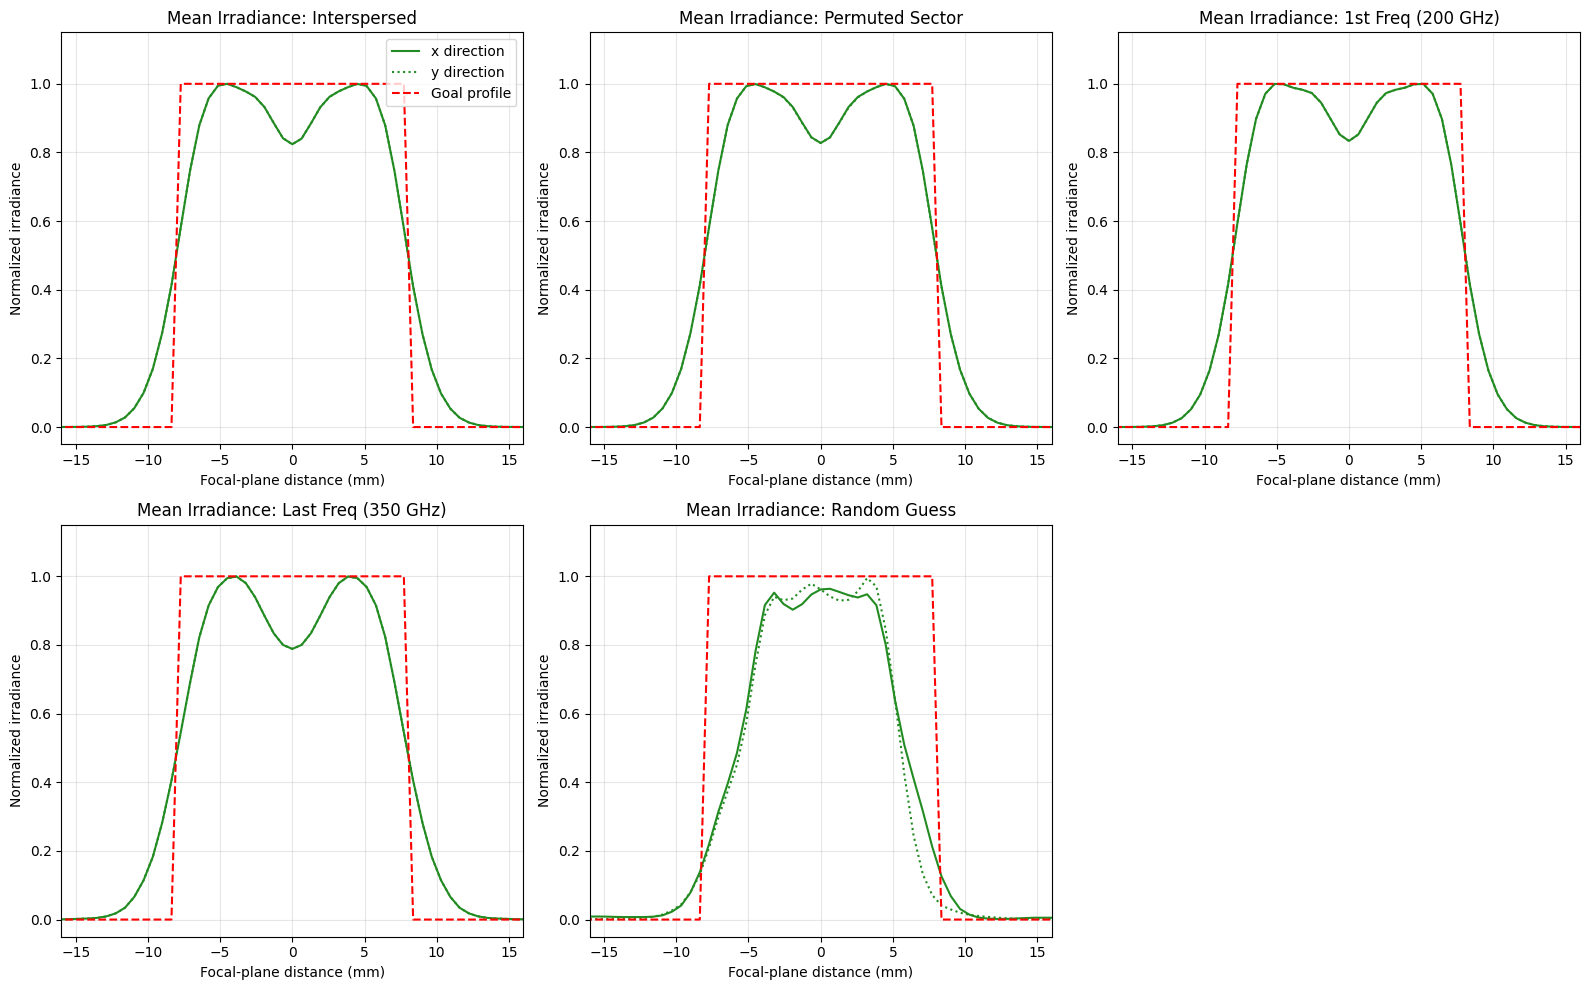

In [22]:

from scipy.ndimage import map_coordinates

# ==========================================
# CROSS-SECTION IRRADIANCE: PHYSICAL COORDINATES
# ==========================================

fig2, axes2 = plt.subplots(2, 3, figsize=(16, 10))
axes2 = axes2.flatten()

num_lenses = len(optimized_freq_2_outputs)

center_idx = params['N'] - 1

wgoal_mm = params['wgoal'] * 1000

# ------------------------------------------
# 1. Calculate focal-plane sampling
# ------------------------------------------

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return wavelength * params['fl'] / (
        shape * dx
    )


# Use the finest sampling among the frequencies
# as the common physical grid.

dxf_values = [
    focal_plane_spacing(f)
    for f in frequencies
]

dxf_common = min(dxf_values)

# Common physical coordinates, centered at zero
x_common = (
    np.arange(shape) - center_idx
) * dxf_common

distance_mm = x_common * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(distance_mm) <= wgoal_mm
).astype(float)


# ==========================================
# 2. RESAMPLE AND AVERAGE ALL FREQUENCIES
# ==========================================

averaged_physical_outputs = []

for lens_idx, title in enumerate(titles):

    freq_Is = optimized_freq_2_outputs[lens_idx]

    resampled_Is = []

    # Common coordinate grid in physical meters
    X_common, Y_common = np.meshgrid(
        x_common,
        x_common,
        indexing='xy'
    )

    # --------------------------------------
    # Interpolate each frequency
    # --------------------------------------

    for f_idx, f in enumerate(frequencies_2):

        I_f = freq_Is[f_idx]

        dxf = focal_plane_spacing(f)

        # Convert common physical coordinates
        # into pixel indices of the original image.

        ix = center_idx + X_common / dxf
        iy = center_idx + Y_common / dxf

        # Bilinear interpolation
        I_resampled = map_coordinates(
            I_f,
            [iy, ix],
            order=1,
            mode='constant',
            cval=0.0
        )

        resampled_Is.append(I_resampled)

    # --------------------------------------
    # Average on the common physical grid
    # --------------------------------------

    avg_I_common = np.mean(
        resampled_Is,
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_common
    )

    # --------------------------------------
    # Plot cross-sections
    # --------------------------------------

    I_norm = avg_I_common / (
        np.max(avg_I_common) + 1e-12
    )

    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile'
    )

    ax.set_title(f"Mean Irradiance: {title}")

    ax.set_xlabel("Focal-plane distance (mm)")
    ax.set_ylabel("Normalized irradiance")

    # Focus on the target and its immediate surroundings
    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(-0.05, 1.15)

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# Turn off unused axes
for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')

plt.tight_layout()
plt.show()



Generating per-frequency plots...


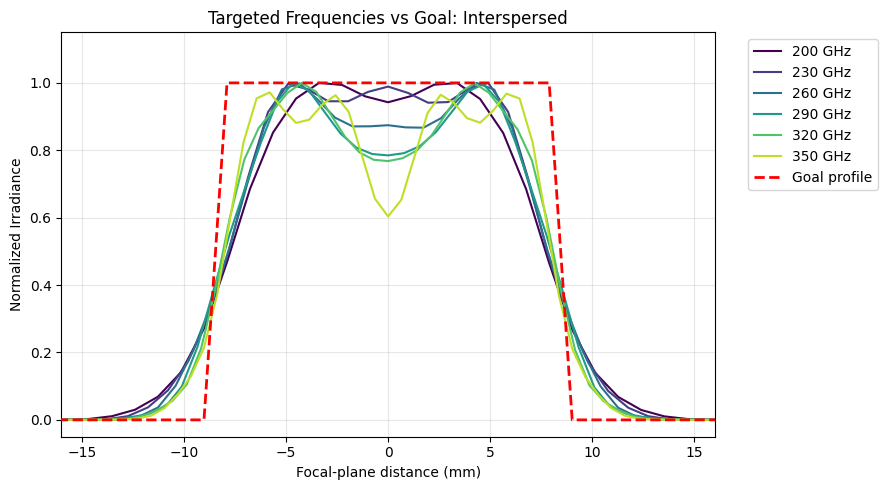

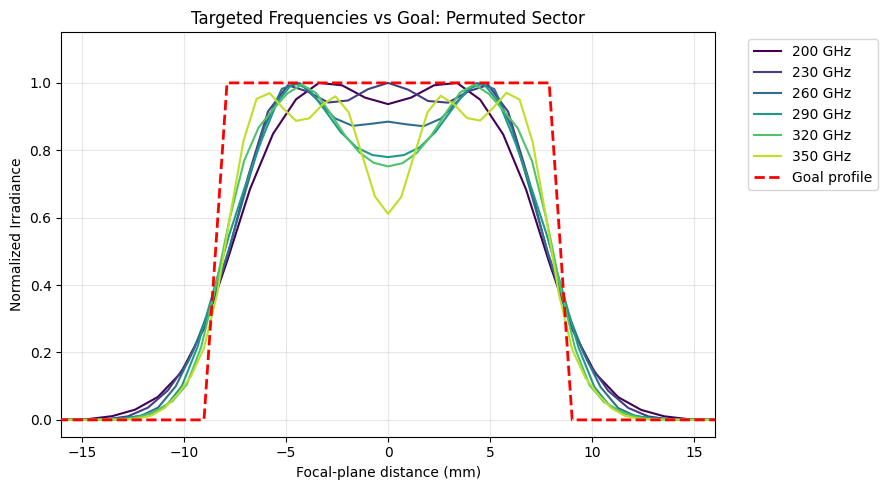

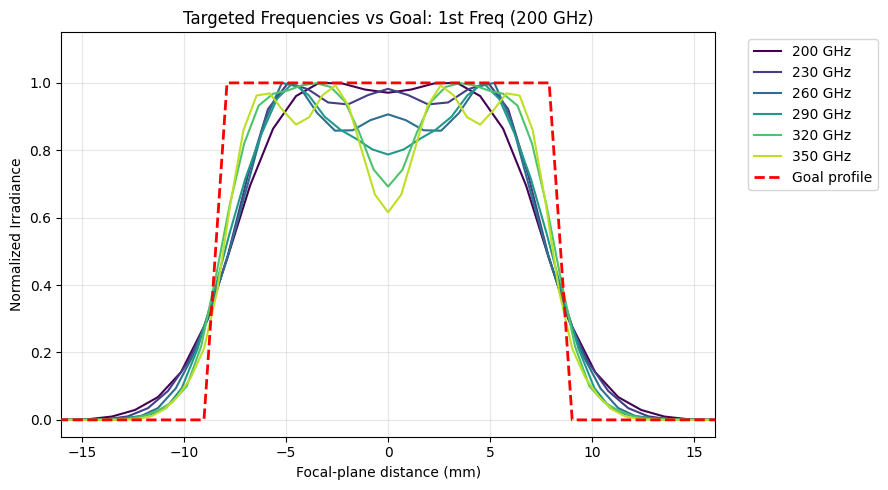

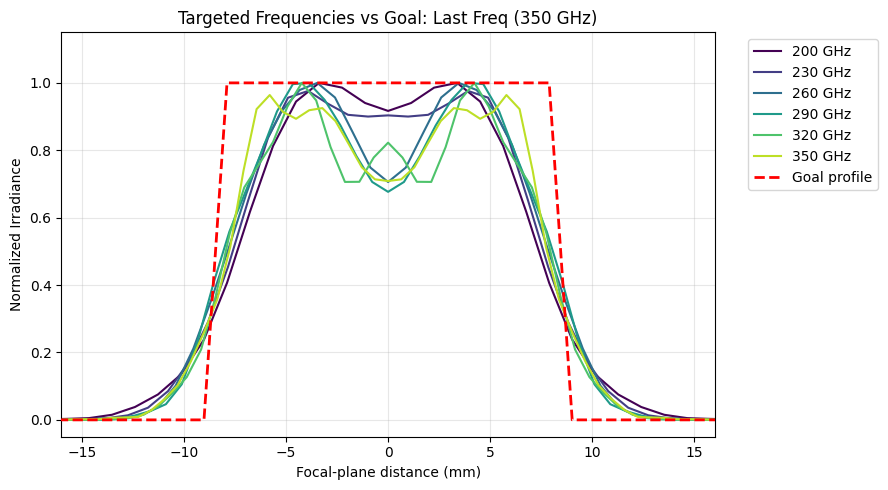

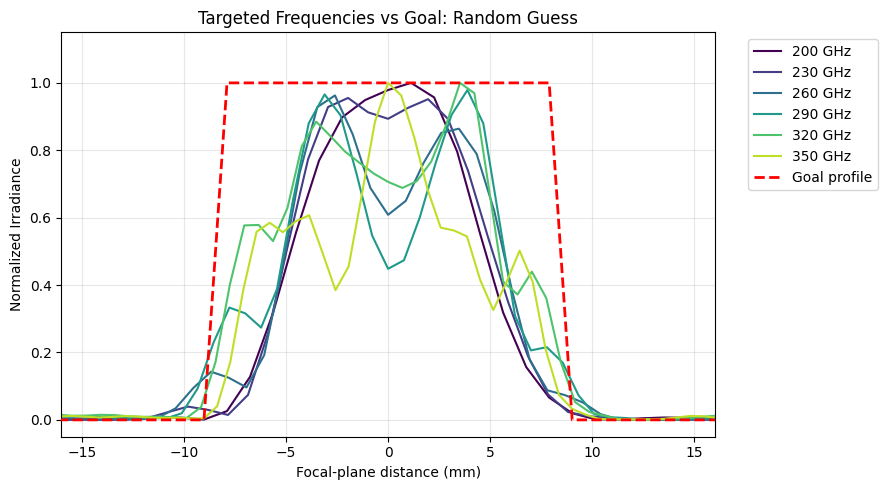

In [23]:

# ==========================================
# 3. PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# Using physical focal-plane coordinates
# ==========================================

print("\nGenerating per-frequency plots...")

center_idx = shape // 2

wgoal_mm = params['wgoal'] * 1000

for lens_idx, (freq_outputs, title) in enumerate(
    zip(optimized_freq_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Generate distinct colors for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies))
    )

    # --------------------------------------
    # Plot each frequency's cross-section
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_outputs, frequencies)
    ):

        # Wavelength
        wavelength = 3e8 / freq_val

        # Correct focal-plane pixel spacing
        dxf = (
            wavelength * params['fl'] /
            (shape * dx)
        )

        # Physical focal-plane coordinates (mm)
        distance_mm_f = (
            np.arange(shape) - center_idx
        ) * dxf * 1000

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central cross-section
        x_slice = I_norm[center_idx, :]

        # Plot intensity profile
        plt.plot(
            distance_mm_f,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Circular uniform target profile
    # --------------------------------------

    # All frequencies have the same physical target radius,
    # although their pixel coordinates are different.

    distance_mm_goal = (
        np.arange(shape) - center_idx
    ) * focal_plane_spacing(frequencies[0]) * 1000

    goal_profile = (
        np.abs(distance_mm_goal) <= wgoal_mm
    ).astype(float)

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Focal-plane distance (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



Generating per-frequency plots...


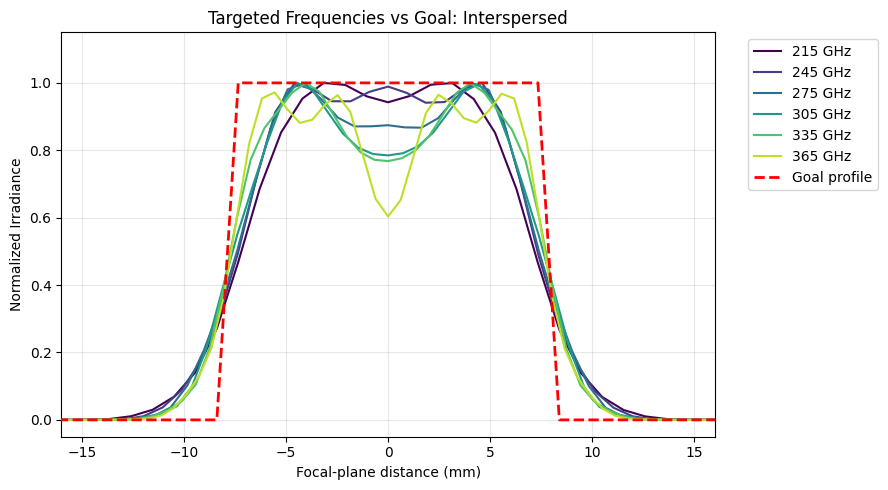

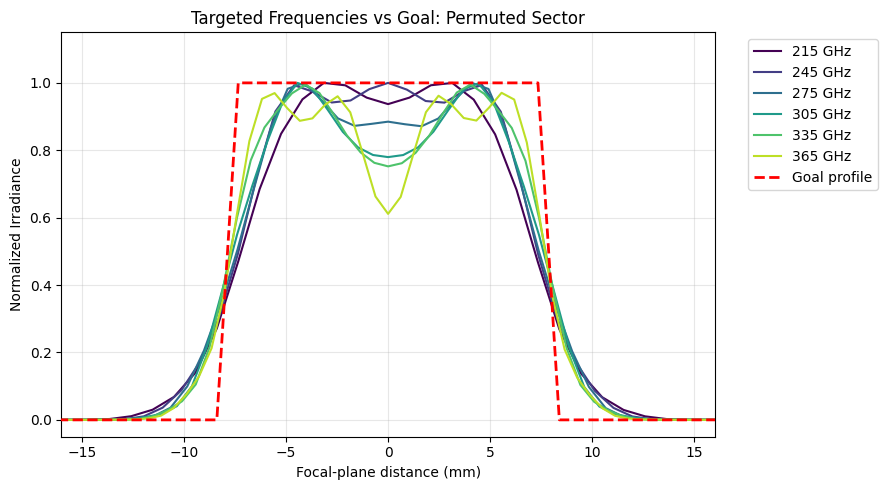

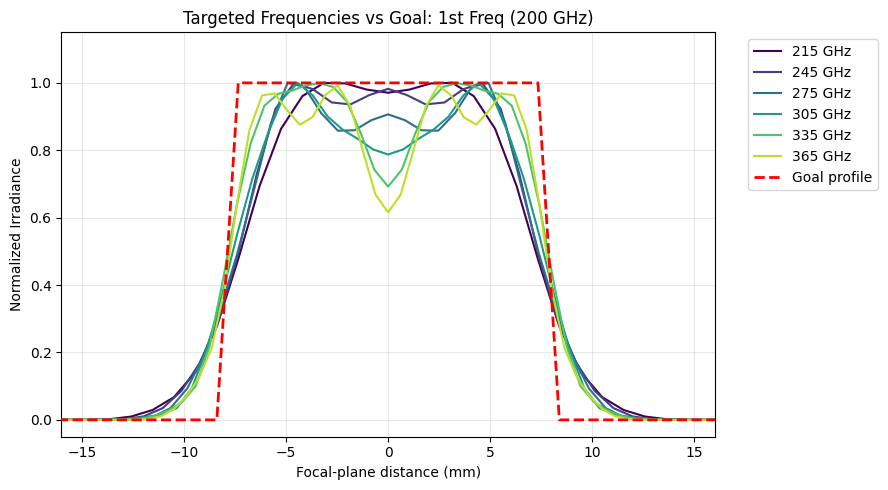

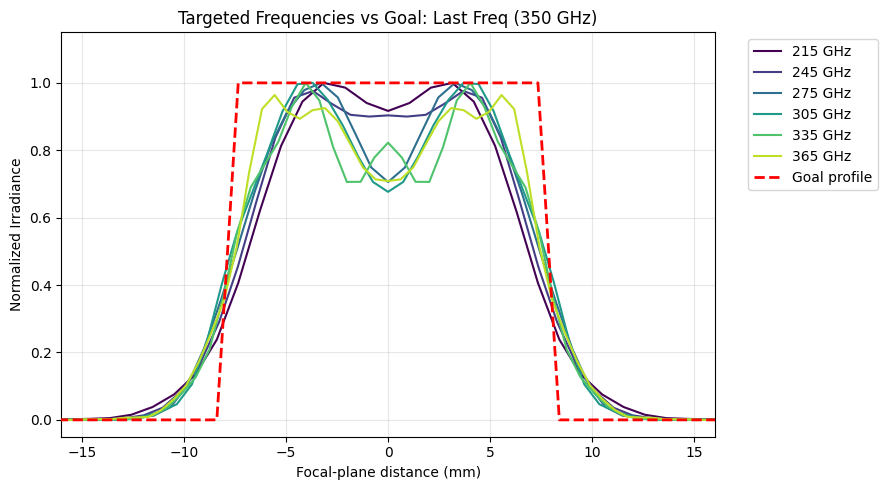

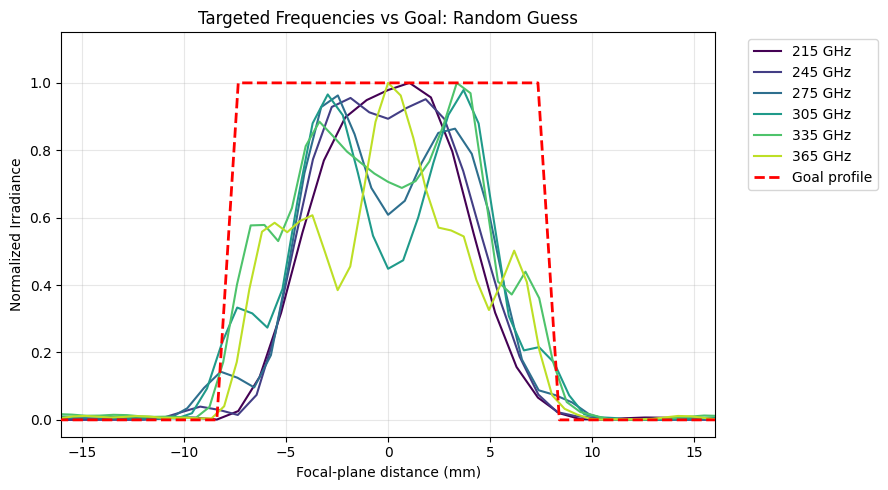

In [24]:

# ==========================================
# 3. PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# Using physical focal-plane coordinates
# ==========================================

print("\nGenerating per-frequency plots...")

center_idx = shape // 2

wgoal_mm = params['wgoal'] * 1000

for lens_idx, (freq_2_outputs, title) in enumerate(
    zip(optimized_freq_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Generate distinct colors for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies_2))
    )

    # --------------------------------------
    # Plot each frequency's cross-section
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_2_outputs, frequencies_2)
    ):

        # Wavelength
        wavelength = 3e8 / freq_val

        # Correct focal-plane pixel spacing
        dxf = (
            wavelength * params['fl'] /
            (shape * dx)
        )

        # Physical focal-plane coordinates (mm)
        distance_mm_f = (
            np.arange(shape) - center_idx
        ) * dxf * 1000

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central cross-section
        x_slice = I_norm[center_idx, :]

        # Plot intensity profile
        plt.plot(
            distance_mm_f,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Circular uniform target profile
    # --------------------------------------

    # All frequencies have the same physical target radius,
    # although their pixel coordinates are different.

    distance_mm_goal = (
        np.arange(shape) - center_idx
    ) * focal_plane_spacing(frequencies_2[0]) * 1000

    goal_profile = (
        np.abs(distance_mm_goal) <= wgoal_mm
    ).astype(float)

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Focal-plane distance (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
